TASK A (Spatial Networks and Planarity)

This notebook invloves constructing and analysing a drivable road network in an approximately 1 km² area around central Leeds, chosen such that it contains a relatively high number of recorded road accidents aggregated across multiple years.

The task requires:
1. identifying the coordinates of the chosen study area,
2. constructing the road network for driving roads only,
3. computing key spatial-network metrics including spatial diameter, average street length, node density, intersection density, edge density, and average circuity,
4. assessing whether the network is planar and explaining the answer.

The analysis follows the module’s spatial-network perspective, where roads are represented as edges and intersections/dead-ends as nodes, while distances are measured along the network rather than only by Euclidean geometry. In the module material, street networks are explicitly treated as spatial networks with edge lengths, node locations, and metrics such as average street length, node density, intersection density, edge density, and circuity. Street networks are also noted to be frequently non-planar in practice because bridges and grade-separated crossings can create edge crossings without true intersections. 

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox

from shapely.geometry import Point, box
from pyproj import Transformer

plt.rcParams["figure.figsize"] = (8, 8)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

Step 1: Load and combine the accident datasets

the task asks us to choose an area around central Leeds with a relatively high number of recorded road accidents aggregated across several years. Therefore, the first step is to load the accident datasets and combine them into a single table.

At this stage, we are not yet analysing time. Instead, we treat the accident records as spatial event points whose locations will help guide study-area selection. This is consistent with the spatial-network viewpoint in the module, where events such as accidents can be analysed as points on or alongside a network. 

In [3]:
# Adjust paths only if your folder structure changes
acc_2014 = pd.read_csv("../../data/raw/accidents_2014.csv", encoding="latin-1")
acc_2015 = pd.read_csv("../../data/raw/accidents_2015.csv", encoding="latin-1")
acc_2016 = pd.read_csv("../../data/raw/accidents_2016.csv", encoding="latin-1")

accidents = pd.concat([acc_2014, acc_2015, acc_2016], ignore_index=True)

print("2014 accidents:", len(acc_2014))
print("2015 accidents:", len(acc_2015))
print("2016 accidents:", len(acc_2016))
print("Combined accidents:", len(accidents))

accidents.head()

2014 accidents: 2533
2015 accidents: 2664
2016 accidents: 2549
Combined accidents: 7746


,Reference Number,Grid Ref: Easting,Grid Ref: Northing,Number of Vehicles,Accident Date,Time (24hr),1st Road Class,Road Surface,Lighting Conditions,Weather Conditions,Casualty Class,Unnamed: 11,Casualty Severity,Sex of Casualty,Age of Casualty,Type of Vehicle,Expr1
0,1112091,429175,431904,2,01-Jan-14,1840,Unclassified,Wet / Damp,Darkness: street lights present and lit,Raining without high winds,1,Driver,Slight,Male,58,Car,NaN
1,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,69,Car,NaN
2,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Female,41,Car,NaN
3,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,35,Car,NaN
4,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,25,Car,NaN


The three yearly datasets have now been merged into one combined accident table. This is the correct starting point for selecting a study area based on multi-year concentration, as requested in the coursework.

Step 2: Convert accident records into a spatial GeoDataFrame

The accident files include British National Grid coordinates (Grid Ref: Easting and Grid Ref: Northing). These are converted into point geometries using the British National Grid CRS (EPSG:27700), which is convenient for distance-based analysis in metres.

This step matters because the later study-area search is not based on names or administrative boundaries, but on the actual spatial distribution of accident events.

In [4]:
# Build geometry from British National Grid coordinates
gdf = gpd.GeoDataFrame(
    accidents.copy(),
    geometry=gpd.points_from_xy(
        accidents["Grid Ref: Easting"],
        accidents["Grid Ref: Northing"]
    ),
    crs="EPSG:27700"
)

print("CRS:", gdf.crs)
gdf.head()

CRS: EPSG:27700


,Reference Number,Grid Ref: Easting,Grid Ref: Northing,Number of Vehicles,Accident Date,Time (24hr),1st Road Class,Road Surface,Lighting Conditions,Weather Conditions,Casualty Class,Unnamed: 11,Casualty Severity,Sex of Casualty,Age of Casualty,Type of Vehicle,Expr1,geometry
0,1112091,429175,431904,2,01-Jan-14,1840,Unclassified,Wet / Damp,Darkness: street lights present and lit,Raining without high winds,1,Driver,Slight,Male,58,Car,NaN,POINT (429175 431904)
1,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,69,Car,NaN,POINT (430429 431025)
2,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Female,41,Car,NaN,POINT (430429 431025)
3,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,35,Car,NaN,POINT (424660 427582)
4,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,25,Car,NaN,POINT (424660 427582)


The accident data is now in a spatial form, with each row represented by a point in projected metre-based coordinates. This allows direct spatial filtering, counting, and plotting.

Step 3: Inspect the overall accident distribution

Before selecting a final area, it is useful to visualise the overall accident distribution across Leeds. This gives a first sanity check that the data loaded correctly and helps confirm that a dense central region exists.

The aim here is not yet to produce a polished result figure, but to support the later methodological decision on area selection.

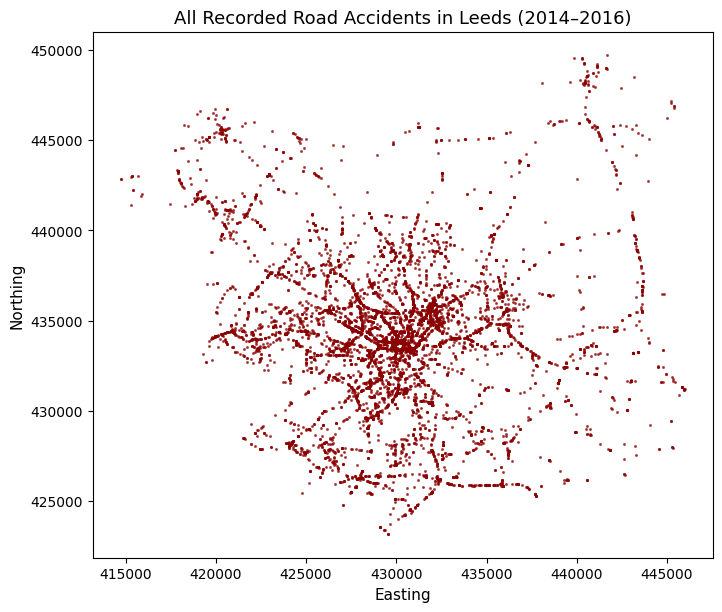

In [5]:
fig, ax = plt.subplots(figsize=(8, 8))
gdf.plot(ax=ax, markersize=1.5, color="darkred", alpha=0.6)
ax.set_title("All Recorded Road Accidents in Leeds (2014–2016)")
ax.set_xlabel("Easting")
ax.set_ylabel("Northing")
plt.show()

The accident pattern shows that events are not uniformly distributed across Leeds. Instead, there are visibly denser zones, which is exactly why a data-driven area selection is preferable to choosing a box arbitrarily.

Step 4: Select a central 1 km² study area with a high accident count

The coursework requires a study area that is:

- approximately 1 square kilometre
- located around the centre of Leeds
- contains a significant number of accidents
- and is selected in a way that can be shown and justified in the report. 

To satisfy this, the approach used here is:

1. define a central search window based on the median accident location, as a practical data-driven approximation to the accident centre of Leeds;
2. slide a 1000 m × 1000 m box across that central region;
3. count the number of accidents inside each candidate box;
4. choose the box with the highest total accident count.

This gives a reproducible justification for the selected area rather than a subjective choice. It also addresses the professor’s instruction to show why this particular area was chosen.

In [6]:
# Use median accident coordinates as a robust proxy for the central accident concentration
central_easting = gdf["Grid Ref: Easting"].median()
central_northing = gdf["Grid Ref: Northing"].median()

print("Central accident proxy (median point):")
print("Easting :", central_easting)
print("Northing:", central_northing)    

Central accident proxy (median point):
Easting : 429934.5
Northing: 434255.5


In [7]:
# Define a central search window around the median point
# This keeps the search around central Leeds instead of scanning the whole city.
search_radius = 3000  # metres

search_min_x = central_easting - search_radius
search_max_x = central_easting + search_radius
search_min_y = central_northing - search_radius
search_max_y = central_northing + search_radius

# Study square is exactly 1 km x 1 km
grid_size = 1000
step = 100  # smaller step gives a more refined search

max_count = -1
best_box = None

for x in np.arange(search_min_x, search_max_x - grid_size + 1, step):
    for y in np.arange(search_min_y, search_max_y - grid_size + 1, step):
        mask = (
            (gdf["Grid Ref: Easting"] >= x) & (gdf["Grid Ref: Easting"] <= x + grid_size) &
            (gdf["Grid Ref: Northing"] >= y) & (gdf["Grid Ref: Northing"] <= y + grid_size)
        )
        count = mask.sum()

        if count > max_count:
            max_count = count
            best_box = (int(x), int(y))

print("Maximum accident count found in a 1 km² candidate box:", max_count)
print("Best box lower-left corner:", best_box)

Maximum accident count found in a 1 km² candidate box: 313
Best box lower-left corner: (429934, 433255)


The search step identifies the central candidate box with the highest multi-year accident count. This is the key evidence for the area-selection decision and should later be described briefly in the report.

If the count is comfortably above the coursework suggestion of roughly 300 accidents, then the selected box satisfies the intended scale and significance requirement. 

In [8]:
# Define the chosen study area precisely
min_easting = best_box[0]
max_easting = min_easting + grid_size
min_northing = best_box[1]
max_northing = min_northing + grid_size

study_box = box(min_easting, min_northing, max_easting, max_northing)

# Accidents inside the chosen box
final_area = gdf.cx[min_easting:max_easting, min_northing:max_northing].copy()

print("Chosen study area accident count:", len(final_area))
print("Chosen area boundaries:")
print("Easting :", min_easting, "to", max_easting)
print("Northing:", min_northing, "to", max_northing)
print("Area (m²):", grid_size * grid_size)
print("Area (km²):", (grid_size * grid_size) / 1_000_000)

Chosen study area accident count: 313
Chosen area boundaries:
Easting : 429934 to 430934
Northing: 433255 to 434255
Area (m²): 1000000
Area (km²): 1.0


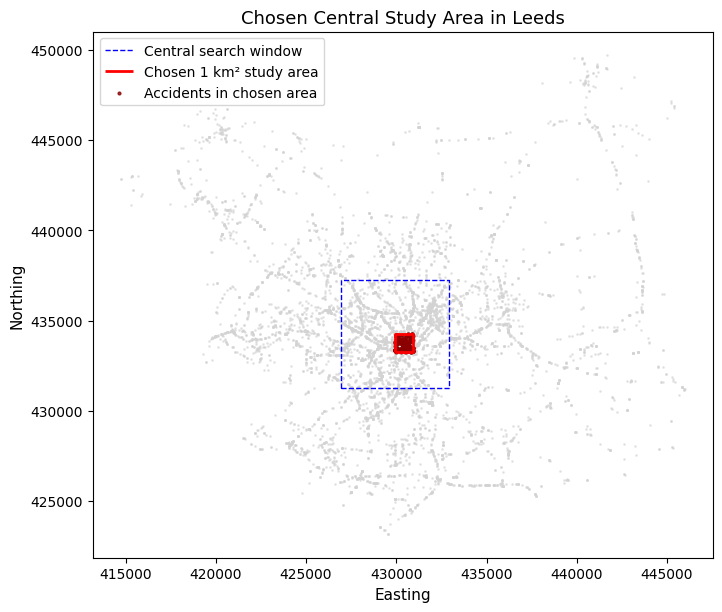

In [9]:
# Plot the selected study area and the accidents inside it
fig, ax = plt.subplots(figsize=(8, 8))

# All accidents in light grey
gdf.plot(ax=ax, markersize=1, color="lightgrey", alpha=0.5)

# Search window (optional visual context)
search_window = box(search_min_x, search_min_y, search_max_x, search_max_y)
gpd.GeoSeries([search_window], crs="EPSG:27700").boundary.plot(
    ax=ax, color="blue", linewidth=1, linestyle="--", label="Central search window"
)

# Selected study box
gpd.GeoSeries([study_box], crs="EPSG:27700").boundary.plot(
    ax=ax, color="red", linewidth=2, label="Chosen 1 km² study area"
)

# Accidents inside chosen box
final_area.plot(ax=ax, markersize=4, color="darkred", alpha=0.8, label="Accidents in chosen area")

ax.set_title("Chosen Central Study Area in Leeds")
ax.set_xlabel("Easting")
ax.set_ylabel("Northing")
ax.legend()
plt.show()

The figure shows both the central search region and the final selected 1 km² box. The chosen area is not arbitrary: it is the highest-accident square found within the central search region, which provides a direct and defensible answer to the professor’s instruction to show why this area was chosen.

This result also confirms that the area is suitable for later accident-network analysis, since the event count is substantial enough to support meaningful spatial interpretation.

Step 5: Convert the study area to latitude/longitude for OpenStreetMap queries

The accident data is stored in British National Grid coordinates, but OpenStreetMap queries in OSMnx operate in WGS84 latitude/longitude coordinates. Therefore, the chosen polygon is converted before extracting the road network.

This conversion is a technical requirement for linking the accident study area to the OSM road network.

In [10]:
# Study area polygon in WGS84
study_box_gdf = gpd.GeoDataFrame(geometry=[study_box], crs="EPSG:27700").to_crs(epsg=4326)
study_polygon_wgs84 = study_box_gdf.geometry.iloc[0]

# Also compute centre point for reporting
center_easting = (min_easting + max_easting) / 2
center_northing = (min_northing + max_northing) / 2

center_point = gpd.GeoSeries([Point(center_easting, center_northing)], crs="EPSG:27700").to_crs(epsg=4326)

center_lon = center_point.x.iloc[0]
center_lat = center_point.y.iloc[0]

print("Study area centre (lat, lon):", center_lat, center_lon)
study_box_gdf

Study area centre (lat, lon): 53.79923035962985 -1.5394285455077332


,geometry
0,"POLYGON ((-1.53189 53.79471, -1.53179 53.80369..."


The selected study area now has both projected metre-based coordinates and geographic latitude/longitude coordinates. The projected coordinates remain useful for spatial measurement, while the geographic coordinates are needed for road-network extraction.

Step 6: Extract the drivable road network from OpenStreetMap

The coursework explicitly states that only roads used for driving should be considered, excluding walking paths and private-road style alternatives as far as possible through OSMnx filtering. A suitable practical choice is therefore network_type="drive", which retrieves the drivable road network rather than pedestrian infrastructure. 

The network is extracted using the chosen polygon, not a circular radius query, so that the road network corresponds as closely as possible to the selected study area.

In [11]:
# Download the drivable road network from OSM for the chosen polygon
G = ox.graph_from_polygon(
    study_polygon_wgs84,
    network_type="drive",
    simplify=True,
    retain_all=False,
    truncate_by_edge=False
)

# Project graph to a metric CRS for distance-based analysis
G_proj = ox.project_graph(G)

print("Projected graph loaded.")
print("Nodes:", nx.number_of_nodes(G_proj))
print("Edges:", nx.number_of_edges(G_proj))

Projected graph loaded.
Nodes: 204
Edges: 347


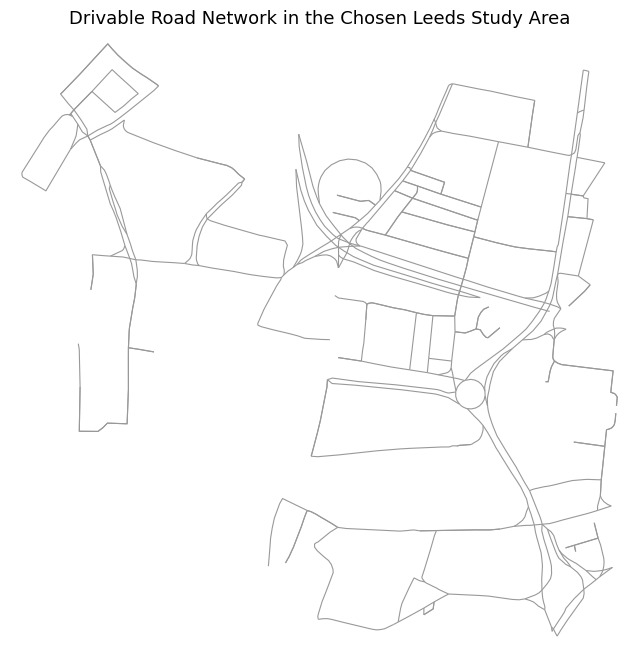

In [12]:
# Plot the road network
fig, ax = ox.plot_graph(
    G_proj,
    node_size=0,
    edge_linewidth=0.8,
    bgcolor="white",
    show=False,
    close=False
)
ax.set_title("Drivable Road Network in the Chosen Leeds Study Area")
plt.show()

The extracted graph represents the drivable road network inside the selected 1 km² study area. At this stage, the accident-selection step and the network-construction step are now aligned: the events and the road graph refer to the same study region.

Step 7: Compute basic spatial network statistics

The lecture materials identify the following as key street-network metrics:

- average street length
- node density
- intersection density
- edge density
- direct spatial distance
- average circuitry. :contentReference[oaicite:8]{index=8}

These are computed using OSMnx summary statistics over the projected graph, with the area supplied in square metres so that density values are normalised properly.

In [13]:
area_m2 = grid_size * grid_size
area_km2 = area_m2 / 1_000_000

stats = ox.basic_stats(G_proj, area=area_m2)
stats

{'n': 204,
 'm': 347,
 'k_avg': 3.4019607843137254,
 'edge_length_total': 21413.917023468413,
 'edge_length_avg': 61.711576436508395,
 'streets_per_node_avg': 2.9754901960784315,
 'streets_per_node_counts': {0: 0, 1: 19, 2: 10, 3: 134, 4: 39, 5: 2},
 'streets_per_node_proportions': {0: 0.0,
  1: 0.09313725490196079,
  2: 0.049019607843137254,
  3: 0.6568627450980392,
  4: 0.19117647058823528,
  5: 0.00980392156862745},
 'intersection_count': 185,
 'street_length_total': 17556.00300714228,
 'street_segment_count': 283,
 'street_length_avg': 62.03534631499039,
 'circuity_avg': 1.0792136122514357,
 'self_loop_proportion': 0.0035335689045936395,
 'node_density_km': 204.0,
 'intersection_density_km': 185.0,
 'edge_density_km': 21413.917023468413,
 'street_density_km': 17556.00300714228}

In [14]:
# Helper to avoid key issues across versions
def get_stat(d, key, default=np.nan):
    return d[key] if key in d else default

num_nodes = get_stat(stats, "n")
num_edges = get_stat(stats, "m")

avg_street_length = get_stat(stats, "street_length_avg")
node_density = get_stat(stats, "node_density_km")
intersection_density = get_stat(stats, "intersection_density_km")
edge_density = get_stat(stats, "edge_density_km")
circuity_avg = get_stat(stats, "circuity_avg")

print("Number of nodes:", num_nodes)
print("Number of edges:", num_edges)
print("Average street length (m):", avg_street_length)
print("Node density (nodes/km²):", node_density)
print("Intersection density (intersections/km²):", intersection_density)
print("Edge density (m of edge per km²):", edge_density)
print("Average circuity:", circuity_avg)

Number of nodes: 204
Number of edges: 347
Average street length (m): 62.03534631499039
Node density (nodes/km²): 204.0
Intersection density (intersections/km²): 185.0
Edge density (m of edge per km²): 21413.917023468413
Average circuity: 1.0792136122514357


These statistics summarise the geometric and structural character of the road network in the chosen study area.

In particular:

- average street length describes the typical size of road segments;
- node density describes how many network nodes occur per square kilometre;
- intersection density better reflects road connectivity and junction intensity;
- edge density describes how much road length is present per square kilometre;
- average circuity compares actual route geometry against straight-line distance, and therefore gives a first indication of routing efficiency. 

Step 8:. Compute the spatial diameter

The module distinguishes spatial diameter from the ordinary unweighted graph diameter. In a spatial graph, edges carry length, so spatial diameter means the greatest shortest-path distance in metres, not merely the greatest number of hops. 

For road networks, this is computed using edge length as the weight. The analysis is applied to the largest connected component of the undirected network so that all node pairs considered are mutually reachable.

In [15]:
# Convert to undirected for spatial reachability analysis
Gu = ox.convert.to_undirected(G_proj)

# Keep only the largest connected component
largest_cc_nodes = max(nx.connected_components(Gu), key=len)
Gu_lcc = Gu.subgraph(largest_cc_nodes).copy()

print("Largest connected component nodes:", Gu_lcc.number_of_nodes())
print("Largest connected component edges:", Gu_lcc.number_of_edges())

Largest connected component nodes: 204
Largest connected component edges: 283


In [16]:
# Compute weighted shortest-path lengths and spatial diameter
all_lengths = dict(nx.all_pairs_dijkstra_path_length(Gu_lcc, weight="length"))
spatial_diameter_m = max(max(lengths.values()) for lengths in all_lengths.values())

print("Spatial diameter (m):", spatial_diameter_m)
print("Spatial diameter (km):", spatial_diameter_m / 1000)

Spatial diameter (m): 2221.6417253713066
Spatial diameter (km): 2.2216417253713066


The spatial diameter gives the maximum shortest drivable distance between two reachable nodes in the study network. Unlike ordinary graph diameter, this value respects the actual geometry and lengths of road segments, which makes it much more meaningful for a street-network interpretation. 

Step 9: Examine average circuitry more directly

The lecture defines circuitry as the relationship between actual path distance and direct spatial distance, that is, how much longer real travel routes are than straight-line travel. Higher circuitry implies more indirect travel, whereas values closer to 1 imply more efficient routing. 

The OSMnx value computed earlier is therefore directly interpretable as a network-efficiency indicator.

In [17]:
print("Average circuity:", circuity_avg)

if pd.notna(circuity_avg):
    if circuity_avg < 1.1:
        interpretation = "very efficient / near-straight routing geometry"
    elif circuity_avg < 1.3:
        interpretation = "moderately efficient routing with some detour"
    else:
        interpretation = "more indirect routing geometry with larger detours"
else:
    interpretation = "circuity could not be computed automatically"

print("Interpretation:", interpretation)

Average circuity: 1.0792136122514357
Interpretation: very efficient / near-straight routing geometry


The computed circuitry value can be used to comment on whether the road structure allows relatively direct travel or whether movement tends to require noticeable detours. This is important because the coursework asks not only for the value itself, but also for an interpretation of what it says about the efficiency of using roads in the area. 

Step 10: Investigate planarity

The lectures define a planar graph as one that can be drawn without edge crossings, and further discuss Kuratowski’s theorem, which states that a graph is planar if and only if it contains no subdivision of (K_5) or (K_{3,3}). 

However, for road networks, there is an important distinction:

- a graph may be topologically planar as an abstract graph,
- while the real street system may still be spatially non-planar because roads can cross at bridges or overpasses without forming intersections. The spatial-network lecture explicitly notes that street networks are often non-planar for exactly this reason. 

Therefore, two complementary checks are used here:

1. a graph-theoretic planarity test using NetworkX;
2. a geometric crossing search on the road segments themselves.

In [18]:
# Graph-theoretic planarity test on a simple undirected version
# A simple graph is used because planarity is usually evaluated on the abstract topology.
G_simple = nx.Graph(Gu_lcc)

is_planar_topological, embedding = nx.check_planarity(G_simple)

print("Topological planarity test result:", is_planar_topological)

Topological planarity test result: False


In [19]:
# Build edge GeoDataFrame for geometric crossing analysis
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G_proj, nodes=True, edges=True)

edges_geom = edges_gdf[["geometry"]].reset_index(drop=False).copy()
edges_geom = edges_geom[edges_geom.geometry.notnull()].reset_index(drop=True)

print("Edge geometries available:", len(edges_geom))
edges_geom.head()

Edge geometries available: 347


,u,v,key,geometry
0,611057,6047609602,0,"LINESTRING (596569.662 5961701.725, 596557.934..."
1,6047609602,26661423,0,"LINESTRING (596557.934 5961731.643, 596553 596..."
2,6047609602,682264890,0,"LINESTRING (596557.934 5961731.643, 596558.193..."
3,643851,1020737601,0,"LINESTRING (596648.235 5961784.492, 596654.382..."
4,1020737601,2377604550,0,"LINESTRING (596654.382 5961789.605, 596676.808..."


In [24]:
print(edges_gdf.total_bounds)

[ 595639.67727593 5961685.3043418   596685.27159988 5962725.57363339]


In [21]:
# Detect geometric crossings among road segments
# crosses() is stronger than intersects(): it captures interior crossings rather than shared endpoints.
crossing_examples = []
sindex = edges_geom.sindex

for i, geom_i in enumerate(edges_geom.geometry):
    candidate_idx = list(sindex.query(geom_i, predicate="intersects"))
    
    for j in candidate_idx:
        if j <= i:
            continue
        
        geom_j = edges_geom.geometry.iloc[j]
        
        if geom_i.crosses(geom_j):
            inter = geom_i.intersection(geom_j)
            crossing_examples.append((i, j, inter))
        
        if len(crossing_examples) >= 10:
            break
    
    if len(crossing_examples) >= 10:
        break

print("Number of geometric crossing examples collected:", len(crossing_examples))
crossing_examples[:3]

Number of geometric crossing examples collected: 10


[(21, np.int64(144), <POINT (596550.985 5962259.839)>),
 (37, np.int64(291), <POINT (596406.534 5962284.547)>),
 (37, np.int64(144), <POINT (596411.163 5962300.327)>)]

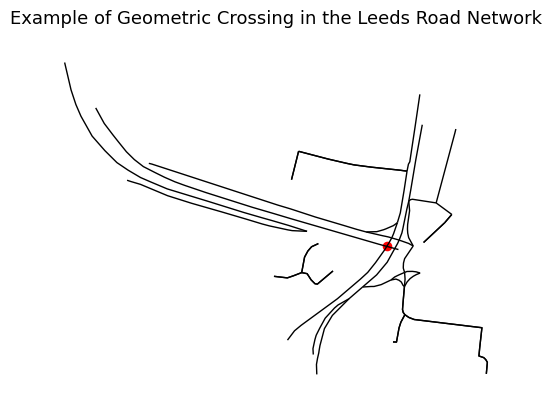

In [26]:
# Zoom to the first detected crossing example
cross_pt = crossing_examples[0][2]

xmin, xmax = cross_pt.x - 120, cross_pt.x + 120
ymin, ymax = cross_pt.y - 120, cross_pt.y + 120

subset_edges = edges_gdf.cx[xmin:xmax, ymin:ymax]

fig, ax = plt.subplots(figsize=(6, 6))
subset_edges.plot(ax=ax, color="black", linewidth=1)
gpd.GeoSeries([cross_pt], crs=edges_gdf.crs).plot(ax=ax, color="red", markersize=35)

ax.set_title("Example of Geometric Crossing in the Leeds Road Network")
ax.set_axis_off()

plt.show()

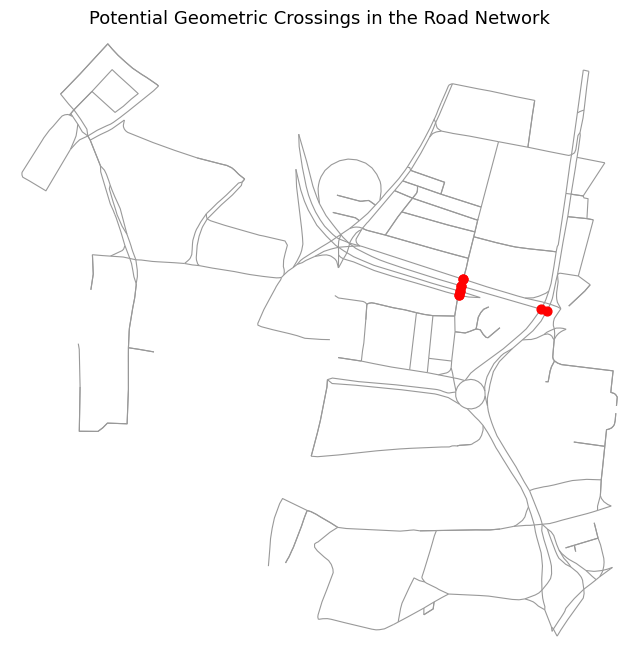

In [22]:
# Plot crossing examples if any are found
fig, ax = ox.plot_graph(
    G_proj,
    node_size=0,
    edge_linewidth=0.8,
    bgcolor="white",
    show=False,
    close=False
)

for _, _, inter in crossing_examples:
    if inter.geom_type == "Point":
        ax.scatter(inter.x, inter.y, color="red", s=40, zorder=5)
    elif inter.geom_type == "MultiPoint":
        for pt in inter.geoms:
            ax.scatter(pt.x, pt.y, color="red", s=40, zorder=5)

ax.set_title("Potential Geometric Crossings in the Road Network")
plt.show()

The planarity section should be interpreted carefully.

- If the topological test returns True, this means the abstract graph can be embedded without crossings.
- If geometric crossings are still visible in the mapped road geometry, then the road system is spatially non-planar in practice, which is entirely consistent with bridges, flyovers, or other grade-separated structures. 
- If the topological test returns False, then the network is already non-planar at the graph-theoretic level.

For the report, the safest interpretation is usually:
the road network should be discussed as a real spatial street system, where planarity is limited by genuine road crossings without intersections, not only by the abstract graph embedding.

Summarising the results in one table

A compact summary table is useful both for the notebook and for later transfer into the report. It also helps with Git version control, because it makes it easy to see whether later code changes altered any of the main results.

In [23]:
taskA_summary = pd.DataFrame({
    "Metric": [
        "Accidents in chosen area",
        "Study area centre latitude",
        "Study area centre longitude",
        "Min Easting",
        "Max Easting",
        "Min Northing",
        "Max Northing",
        "Area (km²)",
        "Number of nodes",
        "Number of edges",
        "Average street length (m)",
        "Node density (nodes/km²)",
        "Intersection density (intersections/km²)",
        "Edge density (m per km²)",
        "Spatial diameter (m)",
        "Spatial diameter (km)",
        "Average circuity",
        "Topologically planar?"
    ],
    "Value": [
        len(final_area),
        center_lat,
        center_lon,
        min_easting,
        max_easting,
        min_northing,
        max_northing,
        area_km2,
        num_nodes,
        num_edges,
        avg_street_length,
        node_density,
        intersection_density,
        edge_density,
        spatial_diameter_m,
        spatial_diameter_m / 1000,
        circuity_avg,
        is_planar_topological
    ]
})

taskA_summary

,Metric,Value
0,Accidents in chosen area,313
1,Study area centre latitude,53.79923
2,Study area centre longitude,-1.539429
3,Min Easting,429934
4,Max Easting,430934
5,Min Northing,433255
6,Max Northing,434255
7,Area (km²),1.0
8,Number of nodes,204
9,Number of edges,347


Final interpretation for Task A

This notebook selected a central 1 km² study area in Leeds using a reproducible search over candidate boxes and chose the one with the highest multi-year accident count within the central search region. This directly addresses the requirement to both justify and demonstrate the study-area choice. 

The extracted drivable road graph then allowed the required Task A measures to be computed:

- coordinates of the chosen area,
- spatial diameter,
- average street length,
- node density,
- intersection density,
- edge density,
- and average circuitry. 

Conceptually, the results should be interpreted as follows:

- higher node and intersection density imply a denser and more junction-rich local street fabric;
- higher edge density implies more total road provision per unit area;
- higher circuitry implies less direct travel and lower routing efficiency;
- spatial diameter captures the longest shortest-path distance in the road system, not just the number of graph hops. 

For planarity, the important conclusion is not merely the NetworkX output, but the distinction between abstract graph planarity and real spatial street-network planarity. Since road bridges and other grade-separated crossings can create geometric crossings without intersections, real road systems are often non-planar in practice even when simplified graph representations may appear planar. 